# Churn bancario: Evaluacion final

Evalua el modelo seleccionado y el baseline en el mismo test. No utilizar este resultado para elegir hiperparametros.

**Estado:** ejecutado el 6 de octubre de 2026; resultados exploratorios revisados en README y docs/ejecuciones.md. Consulta ../docs/metodologia.md.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("bank_churn")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from bank_churn.alertas import configurar_notebook, mostrar_alertas
configurar_notebook()


# Evaluación final

Casos de test: **2,000**. El modelo **supera** el baseline en accuracy.

```text
          accuracy  average_precision   roc_auc
baseline    0.7965            0.20350  0.500000
modelo      0.8100            0.48062  0.775208
```

Las métricas describen esta partición. Revisar recall por clase y matriz de confusión en el JSON; no ajustar parámetros ni thresholds con este test. La definición del churn y la disponibilidad temporal de las features deben confirmarse en la fuente.

## Probabilidades y decisiones

Brier sigmoid **0.1350**, menor que sin calibrar **0.1350**. Brier y log loss combinan calibración y discriminación; ECE depende de los bins. Las tablas de fiabilidad incluyen soporte y omiten bins vacíos. Con umbral fijado en validación **0.18**, se priorizan **849 de 2000 casos**: recall **75.68%**, precisión **36.28%**, coste de error **0.518 unidades por caso**. FN=5.0, FP=1.0 son supuestos ilustrativos, no importes reales ni ahorro de retención. Se muestran todas las políticas sin elegir una nueva con test. BankChurn no encontró IDs compartidos entre train y test; esto por sí solo no acredita independencia por persona.


,modelo,brier,log_loss,ece_10_bins
0,sin_calibrar,0.135031,0.425082,0.021592
1,sigmoid,0.134991,0.424785,0.019943


,politica,umbral,casos,priorizados,tp,fp,fn,tn,precision,recall,coste_error_total,coste_error_por_caso
0,sin_calibrar_05,0.50,2000,120,70,50,337,1543,0.583333,0.171990,1735.0,0.8675
1,sigmoid_05,0.50,2000,173,94,79,313,1514,0.543353,0.230958,1644.0,0.8220
2,umbral_validacion,0.18,2000,849,308,541,99,1052,0.362780,0.756757,1036.0,0.5180
3,priorizar_todos,0.00,2000,2000,407,1593,0,0,0.203500,1.000000,1593.0,0.7965
4,priorizar_ninguno,1.00,2000,0,0,0,407,1593,0.000000,0.000000,2035.0,1.0175


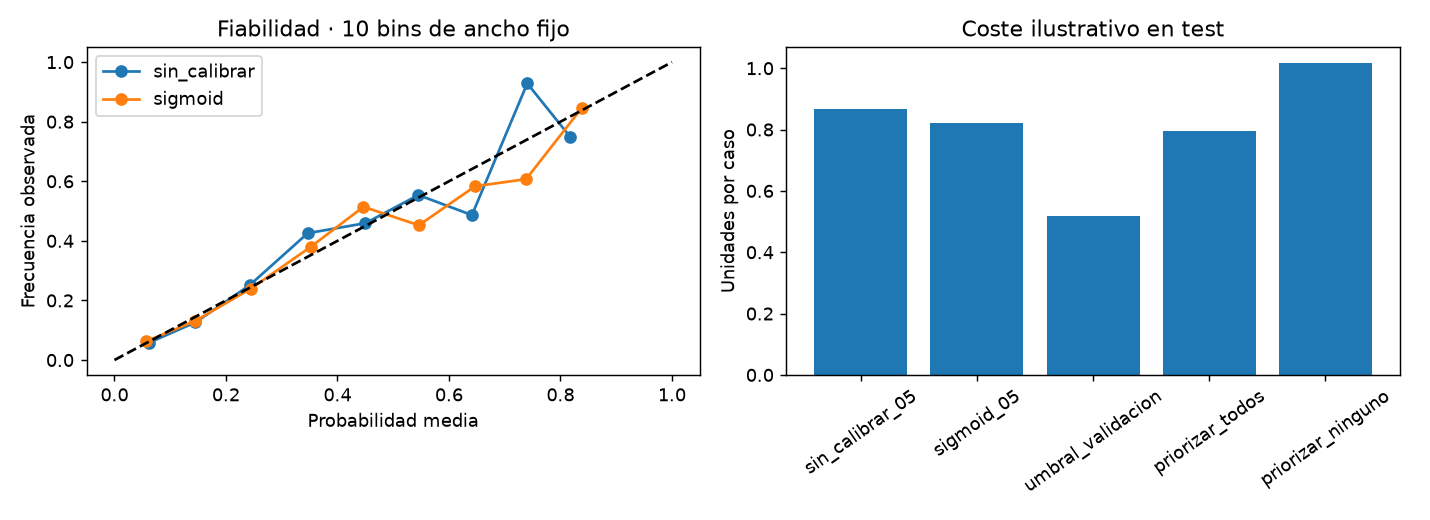

In [2]:
from bank_churn.flujo import evaluar
display(Markdown(evaluar(PROJECT_ROOT)))

from IPython.display import Image
import pandas as pd
display(pd.read_csv(PROJECT_ROOT/"reports/evaluacion/calibracion_test.csv"))
display(pd.read_csv(PROJECT_ROOT/"reports/evaluacion/politicas_test.csv"))
display(Image(filename=str(PROJECT_ROOT/"reports/evaluacion/decisiones.png")))

## Alertas de la ejecucion

Avisos agrupados con descripcion generica, acciones sugeridas y detalle original. Los errores de celda no se ocultan.

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from bank_churn.informe import generar_informe
generar_informe(PROJECT_ROOT)


WindowsPath('D:/portafolio/Analisis/churn/BankChurn/reports/informe_final/informe_final.md')